# Avellaneda-Stoikov evolution, pt. 1: GLFT — BTCUSDT Perpetuals — 2026-11-04

Guéant, Lehalle & Fernandez-Tapia (2013), *"Dealing with the inventory risk: a solution to the market making problem"*,
reworks Avellaneda-Stoikov in two ways that matter in practice:

1. **No terminal time.** AS optimises toward a horizon `T`, so its quotes drift as `T − t` counts down. GLFT solves the
   problem with an inventory cap and looks at the long-horizon (asymptotic) solution: quotes depend on inventory, not on the clock.
2. **Closed-form quotes with an explicit order-arrival model** `λ(δ) = A·e^(−κδ)`, using both `A` and `κ`.

Here we run GLFT and the corrected Avellaneda-Stoikov on the same data, engine, fees and calibration as
[the corrected AS notebook](avellaneda-stoikov-perpetuals-example-corrected.ipynb).

**Exchanges**: Binance · OKX · Hyperliquid · Deribit · **Window**: 10:00–14:00 UTC

## 1. Dependencies

In [1]:
%pip install -q convexlake nautilus_trader plotly pandas kaleido


[notice] A new release of pip is available: 26.1.1 -> 26.3
[notice] To update, run: pip3 install --upgrade pip


Note: you may need to restart the kernel to use updated packages.


## 2. Imports

In [2]:
import io, math, os, pickle, contextlib, warnings
from collections import deque
from datetime import datetime, timezone
from decimal import Decimal
from pathlib import Path

import numpy as np
import pandas as pd
import plotly.graph_objects as go
from IPython.display import Image, display as ipy_display

from convexlake import ConvexLake, NotFoundError, PlanError
from nautilus_trader.backtest.config import BacktestEngineConfig
from nautilus_trader.backtest.engine import BacktestEngine
from nautilus_trader.common.config import LoggingConfig
from nautilus_trader.config import StrategyConfig
from nautilus_trader.model.book import OrderBook
from nautilus_trader.model.currencies import BTC, USDT
from nautilus_trader.model.enums import AccountType, BookType, OmsType, OrderSide, TimeInForce
from nautilus_trader.model.identifiers import InstrumentId, Symbol, Venue
from nautilus_trader.model.instruments import CryptoPerpetual
from nautilus_trader.model.objects import Money, Price, Quantity
from nautilus_trader.trading.strategy import Strategy
from nautilus_trader.analysis.reporter import ReportProvider

warnings.filterwarnings("ignore")

CACHE_DIR = Path("delta_cache")
CACHE_DIR.mkdir(exist_ok=True)
print("imports ok")

imports ok


## 3. Configuration

Units: price $, σ $/√s, γ and κ in 1/$, A in 1/s, inventory `q` in lots (1 lot = 0.001 BTC).

In [3]:
API_KEY = os.environ.get("CONVEXLAKE_API_KEY", "")
if not API_KEY:
    print("WARNING: CONVEXLAKE_API_KEY not set — will use cached data only")

DATE  = "2026-11-04"
START = datetime(2026, 11, 4, 10, 0, tzinfo=timezone.utc)
END   = datetime(2026, 11, 4, 14, 0, tzinfo=timezone.utc)

# (price_precision, size_precision, maker_fee, taker_fee)
VENUE_CFG = {
    "binance":     (1, 3, "0.0002", "0.0004"),
    "okx":         (1, 3, "0.0002", "0.0005"),
    "hyperliquid": (1, 5, "0.0001", "0.0003"),
    "deribit":     (1, 3, "0.0000", "0.0003"),
}

AS_PARAMS = dict(          # corrected model; kappa comes from per-venue calibration (section 6b)
    gamma=1e-4,            # 1/$
    T=3600.0,              # rolling 1-hour horizon, s
    vol_halflife=300.0,    # EWMA half-life for sigma, s
    order_size=0.001,      # BTC per quote = 1 lot
    max_lots=50,           # = 0.05 BTC, same cap as the original
    requote_threshold=0.3,
)

COLORS = {"binance": "#E8A000", "okx": "#1B6CF7", "hyperliquid": "#0080CC", "deribit": "#E05000"}

client = ConvexLake(API_KEY) if API_KEY else None
print(f"date={DATE}  window={START.strftime('%H:%M')}–{END.strftime('%H:%M')} UTC")

GLFT_PARAMS = dict(gamma=1e-4, vol_halflife=300.0, order_size=0.001, max_lots=50, requote_threshold=0.3)
GAMMAS = [3e-5, 1e-4, 3e-4, 1e-3]

date=2026-11-04  window=10:00–14:00 UTC


## 4. Data Sources

S3-verified slugs for 2026-11-04. Sizes are compressed.
Binance is the counter-intuitive case: its `-book` file (42.8 MB) is 8× smaller than `-bbo` (338 MB)
because BBO records every individual quote tick while the book file snapshots periodic depth updates.

In [4]:
# (ticker, slug, compressed_size_mb)
# Bybit has options-only data for this date; Bitfinex requires a higher plan tier.
DATA_SOURCES = {
    "binance":     ("BTCPERP", "BTCPERP-book"),  # 42.8 MB — book < bbo (338 MB) for Binance
    "okx":         ("BTCPERP", "BTCPERP-bbo"),   # 10.5 MB
    "hyperliquid": ("BTCPERP", "BTCPERP-bbo"),   #  0.6 MB
    "deribit":     ("BTCPERP", "BTCPERP-bbo"),   #  6.2 MB
}
print(f"Venues: {list(DATA_SOURCES)}")


Venues: ['binance', 'okx', 'hyperliquid', 'deribit']


## 5. Download & Cache

### ConvexLake SDK → NautilusTrader pipeline

The SDK converts raw S3 data to backtest-ready objects in three stages:

```
orderbook()           → list[dict]            raw S3 messages
to_nautilus()         → pd.DataFrame          int64 fixed-point schema
to_orderbook_deltas() → list[OrderBookDelta]  Cython objects for BacktestEngine
```

**Why filter at the DataFrame stage?**  
`to_orderbook_deltas()` produces Cython objects — iterating 33 M of them to filter by timestamp
takes minutes. A vectorized `df["ts_event"].between(start, end)` on the same 33 M int64 rows
takes milliseconds. So the prefetch script uses the efficient path:

```python
df        = client.download_nautilus(...)          # full day → DataFrame
df_window = df[df["ts_event"].between(start, end)] # vectorized filter, ~instant
deltas    = ConvexLake.to_orderbook_deltas(df_window, ...)  # only create objects we keep
# Binance: 33.9 M total → 5.6 M kept  (468 MB pkl vs 2.6 GB full-day)
```

The notebook loads from these pre-built pickles. On a cache miss it falls back to
`download_orderbook_deltas()` (the full pipeline in one call), which is fine for
the smaller venues (OKX / Hyperliquid / Deribit).

In [5]:
DELTAS: dict[str, list] = {}

for venue, (ticker, slug) in DATA_SOURCES.items():
    pp, sp, _, _ = VENUE_CFG[venue]
    cache_pkl    = CACHE_DIR / f"{venue}_BTCUSDT_{DATE}.pkl"
    iid_str      = f"BTCPERP.{venue.upper()}"

    if cache_pkl.exists():
        with open(cache_pkl, "rb") as f:
            DELTAS[venue] = pickle.load(f)
        print(f"  {venue}: {len(DELTAS[venue]):,} deltas (cache)")
        continue

    print(f"  {venue}/{ticker}/{slug} ...", end=" ", flush=True)
    try:
        # Single SDK call: orderbook() → to_nautilus() → to_orderbook_deltas()
        deltas = client.download_orderbook_deltas(
            exchange=venue, instrument_id=iid_str,
            slug=slug, ticker=ticker, date=DATE,
            price_precision=pp, size_precision=sp,
        )
        print(f"{len(deltas):,} deltas ✓")
        with open(cache_pkl, "wb") as f:
            pickle.dump(deltas, f)
        DELTAS[venue] = deltas
    except (NotFoundError, PlanError) as e:
        print(f"skipped — {type(e).__name__}")
    except Exception as e:
        print(f"error: {e}")

print(f"\nLoaded: {list(DELTAS)}")


  binance: 5,639,468 deltas (cache)


  okx: 273,525 deltas (cache)
  hyperliquid: 8,004 deltas (cache)
  deribit: 127,446 deltas (cache)

Loaded: ['binance', 'okx', 'hyperliquid', 'deribit']


## 4. Order-book reconstruction

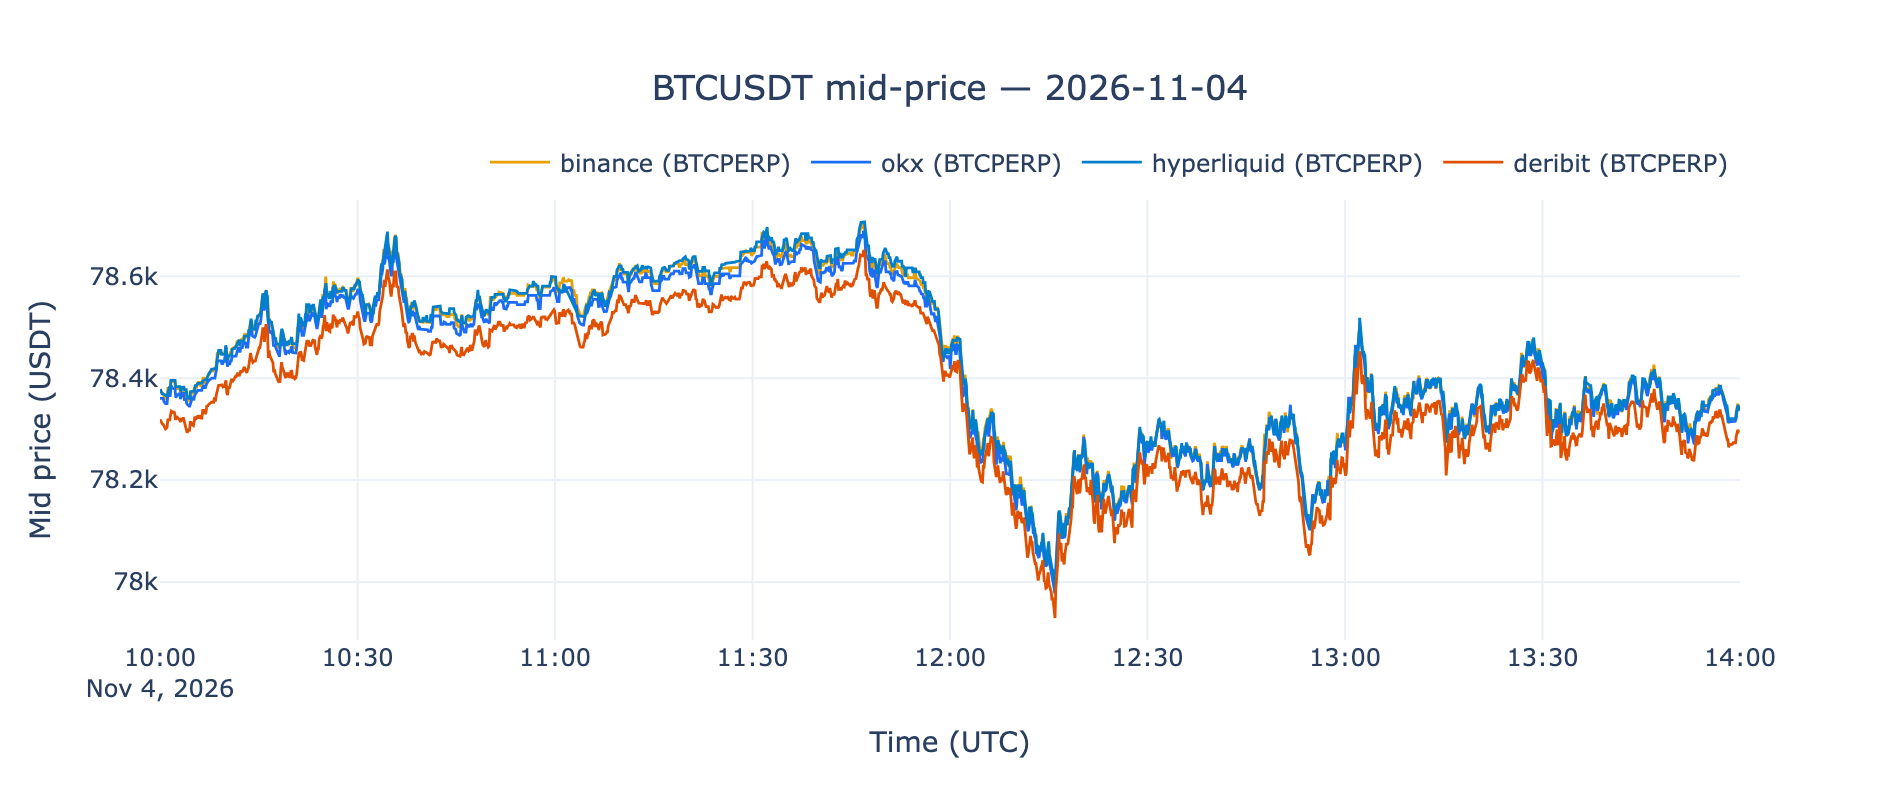

In [6]:
_ACTION_CLEAR, _ACTION_DELETE, _SIDE_BUY = 4, 3, 1

def reconstruct_bbo(deltas):
    """Walk deltas inside the window and return an array of (ts_seconds, bid, ask) at each snapshot boundary."""
    s0, s1 = int(START.timestamp() * 1e9), int(END.timestamp() * 1e9)
    bids, asks, rows = {}, {}, []
    for d in deltas:
        if not (s0 <= d.ts_event <= s1):
            continue
        action = int(d.action)
        if action == _ACTION_CLEAR:
            bids.clear(); asks.clear(); continue
        if d.order is None:
            continue
        book = bids if int(d.order.side) == _SIDE_BUY else asks
        price, size = float(d.order.price), float(d.order.size)
        if action == _ACTION_DELETE or size == 0:
            book.pop(price, None)
        else:
            book[price] = size
        if int(d.flags) & 1 and bids and asks:
            b, a = max(bids), min(asks)
            if b < a:
                rows.append((d.ts_event / 1e9, b, a))
    return np.array(rows)

BBO = {v: reconstruct_bbo(d) for v, d in DELTAS.items()}

fig = go.Figure()
for venue, arr in BBO.items():
    step = max(1, len(arr) // 2000)
    t = [datetime.fromtimestamp(x, tz=timezone.utc) for x in arr[::step, 0]]
    fig.add_trace(go.Scatter(x=t, y=(arr[::step, 1] + arr[::step, 2]) / 2, name=f"{venue} (BTCPERP)",
                             line=dict(color=COLORS.get(venue, "#888"), width=1.4)))
fig.update_layout(title=dict(text=f"BTCUSDT mid-price — {DATE}", x=0.5), template="plotly_white", height=400,
                  xaxis_title="Time (UTC)", yaxis_title="Mid price (USDT)",
                  legend=dict(orientation="h", yanchor="bottom", y=1.02, xanchor="right", x=1))
fig.show()
ipy_display(Image(fig.to_image(format="png", scale=2, width=950)))

## 6b. Calibration: σ, A, κ per venue

Avellaneda-Stoikov needs κ in the same units as prices. We estimate it from the data rather than pick it:

* **σ** — realized volatility of the mid sampled on a 1-second clock, in $/√s.
* **λ(δ) = A·e^(−κδ)** — a fill proxy: how often (per second) the opposite best quote reaches a level
  δ dollars away from the current mid within 1 second. A log-linear fit across δ gives **A** (1/s) and **κ** (1/$).


In [7]:
def calibrate(arr, deltas=(0.5, 1, 2, 3, 5, 8, 12, 18, 25), tau=1.0, stride=5):
    t, b, a = arr[:, 0], arr[:, 1], arr[:, 2]
    mid = (a + b) / 2
    grid = np.arange(t[0], t[-1], 1.0)
    idx = np.searchsorted(t, grid, side="right") - 1
    m1 = mid[idx]
    sigma = float(np.sqrt(np.mean(np.diff(m1) ** 2)))
    j_end = np.searchsorted(t, grid + tau, side="right")
    rates = []
    starts = range(0, len(grid), stride)
    for dd in deltas:
        hits = 0
        for i in starts:
            lo, hi = idx[i] + 1, j_end[i]
            if hi <= lo:
                continue
            hits += (b[lo:hi].max() >= m1[i] + dd) + (a[lo:hi].min() <= m1[i] - dd)
        rates.append(hits / (2 * len(starts)) / tau)
    rates = np.array(rates); dl = np.array(deltas); ok = rates > 0
    slope, icpt = np.polyfit(dl[ok], np.log(rates[ok]), 1)
    return {"sigma": sigma, "A": float(np.exp(icpt)), "kappa": float(-slope),
            "median_spread": float(np.median(a - b)), "lambda": dict(zip(deltas, rates))}

CAL = {v: calibrate(arr) for v, arr in BBO.items()}
print(f"{'Venue':<12} {'sigma $/sqrt(s)':>16} {'A 1/s':>8} {'kappa 1/$':>10} {'median spread $':>16}")
for v, c in CAL.items():
    print(f"{v:<12} {c['sigma']:>16.3f} {c['A']:>8.3f} {c['kappa']:>10.4f} {c['median_spread']:>16.2f}")

Venue         sigma $/sqrt(s)    A 1/s  kappa 1/$  median spread $
binance                 4.079    0.180     0.2069             0.10
okx                     4.013    0.170     0.2031             0.10
hyperliquid             3.912    0.057     0.1271             1.00
deribit                 4.496    0.230     0.2014             0.50


## 5. Shared quoting base + corrected Avellaneda-Stoikov (baseline)

In [8]:
class ASConfig(StrategyConfig, frozen=True):
    instrument_id:     str
    gamma:             float = 1e-4
    kappa:             float = 0.2
    T:                 float = 3600.0
    vol_halflife:      float = 300.0
    order_size:        float = 0.001
    max_lots:          int   = 50
    requote_threshold: float = 0.3


class _QuotingBase(Strategy):
    """Shared plumbing: order-book subscription, inventory, requote logic, EWMA dollar volatility."""
    def _setup(self, config, vol_halflife=300.0):
        self.iid = InstrumentId.from_str(config.instrument_id)
        self.order_size, self.requote_thr = config.order_size, config.requote_threshold
        self._last_bid = self._last_ask = 0.0
        self._t0 = 0
        self._var = self._last_s = self._last_mid = None
        self._alpha = 1 - 0.5 ** (1.0 / vol_halflife)

    def on_start(self):
        self._instrument = self.cache.instrument(self.iid)
        self.subscribe_order_book_deltas(self.iid, book_type=BookType.L2_MBP)
        self._t0 = self.clock.timestamp_ns()

    def on_stop(self):
        self.cancel_all_orders(self.iid)

    def _mid(self):
        book: OrderBook = self.cache.order_book(self.iid)
        if book is None:
            return None
        b, a = book.best_bid_price(), book.best_ask_price()
        return None if b is None or a is None else (float(b) + float(a)) / 2.0

    def _sigma(self, mid):
        """EWMA of squared mid changes on a 1-second clock -> $/sqrt(s)."""
        now = self.clock.timestamp_ns() / 1e9
        if self._last_s is None:
            self._last_s, self._last_mid = now, mid
            return None
        if now - self._last_s >= 1.0:
            v = (mid - self._last_mid) ** 2 / (now - self._last_s)
            self._var = v if self._var is None else (1 - self._alpha) * self._var + self._alpha * v
            self._last_s, self._last_mid = now, mid
        return None if self._var is None else math.sqrt(self._var)

    def _inventory_btc(self):
        ps = self.cache.positions_open(instrument_id=self.iid)
        return 0.0 if not ps else float(ps[0].quantity) * (1 if ps[0].is_long else -1)

    def _should_requote(self, nb, na, spread):
        if not self._last_bid or not self._last_ask:
            return True
        return abs(nb - self._last_bid) > self.requote_thr * spread or abs(na - self._last_ask) > self.requote_thr * spread

    def _requote(self, bid, ask, max_inv_btc):
        inv = self._inventory_btc()
        self.cancel_all_orders(self.iid)
        pp, sp = self._instrument.price_precision, self._instrument.size_precision
        if inv < max_inv_btc:
            self.submit_order(self.order_factory.limit(instrument_id=self.iid, order_side=OrderSide.BUY,
                quantity=Quantity(self.order_size, sp), price=Price(round(bid, pp), pp),
                time_in_force=TimeInForce.GTC, post_only=True))
            self._last_bid = bid
        if inv > -max_inv_btc:
            self.submit_order(self.order_factory.limit(instrument_id=self.iid, order_side=OrderSide.SELL,
                quantity=Quantity(self.order_size, sp), price=Price(round(ask, pp), pp),
                time_in_force=TimeInForce.GTC, post_only=True))
            self._last_ask = ask


class AvellanedaStoikov(_QuotingBase):
    def __init__(self, config: ASConfig):
        super().__init__(config)
        self._setup(config, config.vol_halflife)
        self.gamma, self.kappa, self.T, self.max_lots = config.gamma, config.kappa, config.T, config.max_lots

    def on_order_book_deltas(self, deltas):
        mid = self._mid()
        if mid is None:
            return
        sigma = self._sigma(mid)
        if sigma is None:
            return
        elapsed = (self.clock.timestamp_ns() - self._t0) / 1e9
        t_left = self.T - (elapsed % self.T)                     # rolling horizon
        q = self._inventory_btc() / self.order_size              # lots
        r = mid - q * self.gamma * sigma ** 2 * t_left           # $
        s = self.gamma * sigma ** 2 * t_left + (2.0 / self.gamma) * math.log(1.0 + self.gamma / self.kappa)
        nb, na = r - s / 2.0, r + s / 2.0
        if self._should_requote(nb, na, s):
            self._requote(nb, na, self.max_lots * self.order_size)

print("AvellanedaStoikov (corrected) defined")

AvellanedaStoikov (corrected) defined


## 6. Strategy: GLFT

Closed-form approximation (Guéant 2017), with ξ = γ and lot size Δ = 1:

```
c1 = (1/γ) · ln(1 + γ/κ)
c2 = sqrt( γ / (2·A·κ) · (1 + γ/κ)^(κ/γ + 1) )

half-spread = c1 + ½·σ·c2          (does not depend on inventory or the clock)
skew        = σ·c2   per lot of inventory

bid = s − half-spread − skew·q
ask = s + half-spread − skew·q
```

Compare with AS: AS's spread has a `γ·σ²·(T−t)` term that grows and shrinks with the horizon clock, and its
inventory skew `q·γ·σ²·(T−t)` is largest at the start of each horizon and vanishes at the end.

In [9]:
def glft_coeffs(gamma, kappa, A, delta=1.0):
    c1 = (1.0 / (gamma * delta)) * math.log(1.0 + gamma * delta / kappa)
    c2 = math.sqrt(gamma / (2.0 * A * delta * kappa) * (1.0 + gamma * delta / kappa) ** (kappa / (gamma * delta) + 1.0))
    return c1, c2


class GLFTConfig(StrategyConfig, frozen=True):
    instrument_id:     str
    gamma:             float = 1e-4
    kappa:             float = 0.2
    A:                 float = 0.18
    vol_halflife:      float = 300.0
    order_size:        float = 0.001
    max_lots:          int   = 50
    requote_threshold: float = 0.3


class GLFT(_QuotingBase):
    def __init__(self, config: GLFTConfig):
        super().__init__(config)
        self._setup(config, config.vol_halflife)
        self.max_lots = config.max_lots
        self.c1, self.c2 = glft_coeffs(config.gamma, config.kappa, config.A)

    def on_order_book_deltas(self, deltas):
        mid = self._mid()
        if mid is None:
            return
        sigma = self._sigma(mid)
        if sigma is None:
            return
        q = self._inventory_btc() / self.order_size
        half = self.c1 + 0.5 * sigma * self.c2
        skew = sigma * self.c2
        nb, na = mid - half - skew * q, mid + half - skew * q
        if self._should_requote(nb, na, 2 * half):
            self._requote(nb, na, self.max_lots * self.order_size)

print("GLFT defined")

GLFT defined


## 7. Quote geometry: what each model would quote

Using each venue's calibrated σ, A, κ and γ = 1e-4. AS is shown at the start (`T−t` = 3600 s) and near the end
(`T−t` = 60 s) of its horizon, with 0 and 10 lots of inventory.

In [10]:
rows = []
g = GLFT_PARAMS["gamma"]
for v, c in CAL.items():
    c1, c2 = glft_coeffs(g, c["kappa"], c["A"])
    s = c["sigma"]
    as_half = lambda tl: 0.5 * (g * s**2 * tl + (2 / g) * math.log(1 + g / c["kappa"]))
    rows.append({"venue": v, "GLFT half-spread $": c1 + 0.5 * s * c2, "GLFT skew $/lot": s * c2,
                 "AS half-spread $ (T-t=3600)": as_half(3600), "AS half-spread $ (T-t=60)": as_half(60),
                 "AS skew $/lot (T-t=3600)": g * s**2 * 3600, "AS skew $/lot (T-t=60)": g * s**2 * 60})
GEOM = pd.DataFrame(rows).set_index("venue")
print(GEOM.to_string(float_format="{:.3f}".format))

             GLFT half-spread $  GLFT skew $/lot  AS half-spread $ (T-t=3600)  AS half-spread $ (T-t=60)  AS skew $/lot (T-t=3600)  AS skew $/lot (T-t=60)
venue                                                                                                                                                     
binance                   4.955            0.246                        7.827                      4.882                     5.989                   0.100
okx                       5.050            0.252                        7.823                      4.972                     5.798                   0.097
hyperliquid               8.132            0.535                       10.619                      7.910                     5.509                   0.092
deribit                   5.085            0.244                        8.602                      5.023                     7.278                   0.121


## 8. Instrument Factory & Backtest Runner

One isolated `BacktestEngine` per run, $100k USDT margin account. The runner also returns fill count,
fees paid (from the fills report) and the largest absolute inventory reached.

In [11]:
_no_log = LoggingConfig(log_level="OFF", log_level_file="OFF", bypass_logging=True)

def make_instrument(venue: str) -> CryptoPerpetual:
    pp, sp, maker, taker = VENUE_CFG[venue]
    return CryptoPerpetual(
        instrument_id    = InstrumentId(Symbol("BTCPERP"), Venue(venue.upper())),
        raw_symbol       = Symbol("BTCPERP"),
        base_currency    = BTC,
        quote_currency   = USDT,
        settlement_currency = USDT,
        is_inverse       = False,
        price_precision  = pp,
        price_increment  = Price(10 ** -pp, pp),
        size_precision   = sp,
        size_increment   = Quantity(10 ** -sp, sp),
        multiplier       = Quantity(1, 0),
        lot_size         = Quantity(1, 0),
        margin_init      = Decimal("0.05"),
        margin_maint     = Decimal("0.025"),
        maker_fee        = Decimal(maker),
        taker_fee        = Decimal(taker),
        ts_event         = 0,
        ts_init          = 0,
    )

print("instrument factory ready")


def run_backtest(venue, deltas, strategy):
    s0, s1 = int(START.timestamp() * 1e9), int(END.timestamp() * 1e9)
    window = [d for d in deltas if s0 <= d.ts_event <= s1]
    with contextlib.redirect_stderr(io.StringIO()):
        eng = BacktestEngine(config=BacktestEngineConfig(trader_id="AS-001", logging=_no_log))
        eng.add_venue(venue=Venue(venue.upper()), oms_type=OmsType.NETTING, account_type=AccountType.MARGIN,
                      starting_balances=[Money(100_000, USDT)], book_type=BookType.L2_MBP)
        eng.add_instrument(make_instrument(venue))
        eng.add_data(window)
        eng.add_strategy(strategy)
        eng.run(start=START, end=END)
    report = ReportProvider.generate_account_report(eng.cache.account_for_venue(Venue(venue.upper())))
    fills = eng.trader.generate_order_fills_report()
    eng.dispose()
    usdt = report[report["currency"] == "USDT"][["total"]].copy()
    usdt["pnl"] = usdt["total"].astype(float) - 100_000
    fees, pos, max_inv = 0.0, 0.0, 0.0
    if len(fills):
        for cm in fills["commissions"]:
            for m in (cm if isinstance(cm, list) else [cm]):
                fees += float(str(m).split()[0])
        f2 = fills.sort_values("ts_last")
        for side, qty in zip(f2["side"], f2["filled_qty"]):
            pos += float(qty) * (1 if str(side).upper().endswith("BUY") else -1)
            max_inv = max(max_inv, abs(pos))
    return {"equity": usdt, "final": float(usdt["pnl"].iloc[-1]), "fills": len(fills), "fees": fees,
            "gross": float(usdt["pnl"].iloc[-1]) + fees, "peak": float(usdt["pnl"].max()), "max_inv": max_inv}

print("runner ready")

instrument factory ready
runner ready


## 8. Backtest: corrected AS vs GLFT (γ = 1e-4, calibrated κ and A)

                   net_pnl     fees  gross_pnl  fills  gross_per_fill  peak_pnl  max_inv_btc
venue       model                                                                           
binance     AS    -10.9910  +6.0894    -4.9016    388         -0.0126   +0.0000      +0.0130
            GLFT  -46.2649 +33.7221   -12.5428   2152         -0.0058   +0.0000      +0.0120
okx         AS    -11.7143  +7.0773    -4.6370    451         -0.0103   +0.0000      +0.0100
            GLFT  -44.0492 +32.4193   -11.6299   2069         -0.0056   +0.0000      +0.0120
hyperliquid AS     -5.8942  +1.7962    -4.0980    229         -0.0179   +0.0000      +0.0150
            GLFT  -12.6133  +5.3201    -7.2932    680         -0.0107   +0.0000      +0.0110
deribit     AS     -3.3859  +0.0000    -3.3859    408         -0.0083   +0.6337      +0.0110
            GLFT  -10.7014  +0.0000   -10.7014   2643         -0.0040   +0.0044      +0.0100


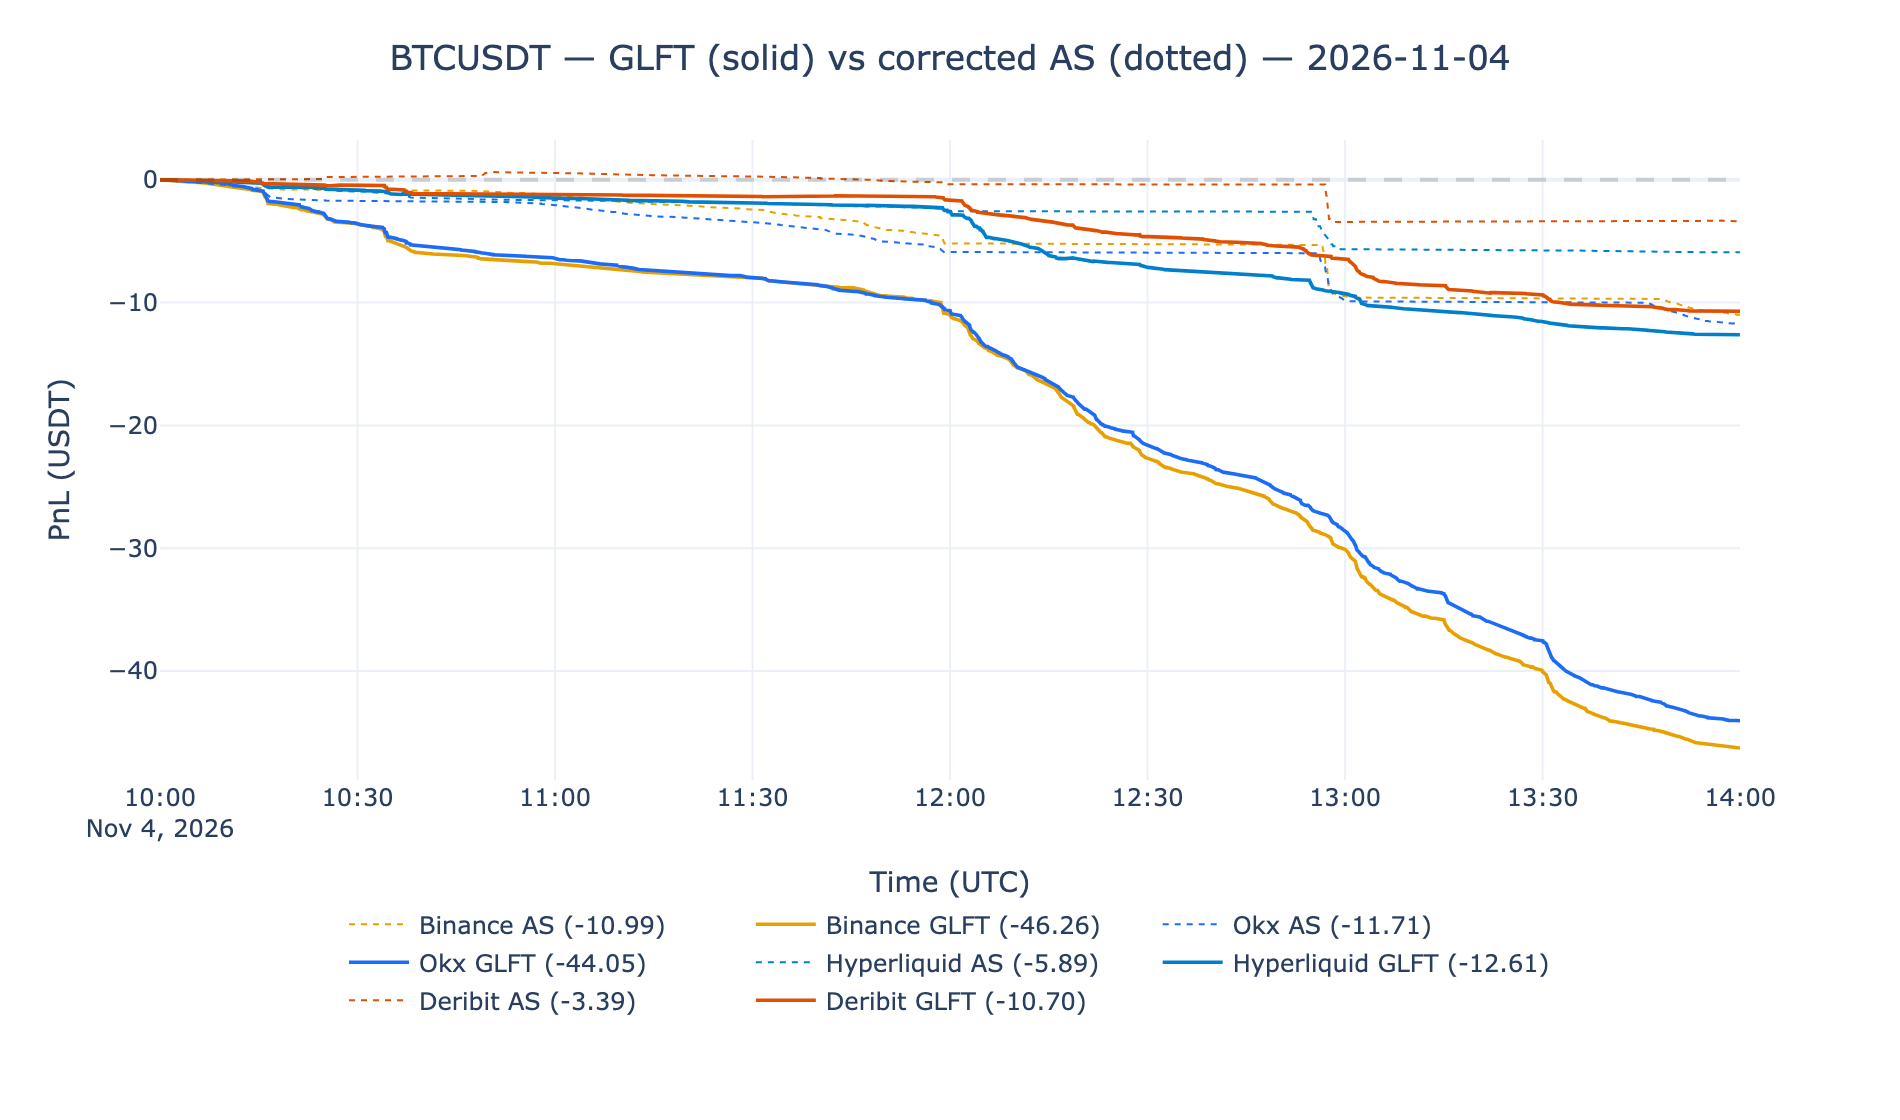

In [12]:
RESULTS = {}
for venue, deltas in DELTAS.items():
    iid, c = f"BTCPERP.{venue.upper()}", CAL[venue]
    RESULTS[(venue, "AS")] = run_backtest(venue, deltas, AvellanedaStoikov(
        ASConfig(instrument_id=iid, kappa=c["kappa"], **AS_PARAMS)))
    RESULTS[(venue, "GLFT")] = run_backtest(venue, deltas, GLFT(
        GLFTConfig(instrument_id=iid, kappa=c["kappa"], A=c["A"], **GLFT_PARAMS)))

SUMMARY = pd.DataFrame([{"venue": v, "model": m, "net_pnl": r["final"], "fees": r["fees"], "gross_pnl": r["gross"],
                         "fills": r["fills"], "gross_per_fill": r["gross"] / max(r["fills"], 1),
                         "peak_pnl": r["peak"], "max_inv_btc": r["max_inv"]}
                        for (v, m), r in RESULTS.items()]).set_index(["venue", "model"])
print(SUMMARY.to_string(float_format="{:+.4f}".format))

fig = go.Figure()
for (venue, model), r in RESULTS.items():
    df = r["equity"]
    fig.add_trace(go.Scatter(x=df.index.strftime("%Y-%m-%dT%H:%M:%S").tolist(), y=df["pnl"],
        name=f"{venue.capitalize()} {model} ({r['final']:+.2f})",
        line=dict(color=COLORS.get(venue, "#888"), width=1.8 if model == "GLFT" else 1.0,
                  dash="solid" if model == "GLFT" else "dot")))
fig.add_hline(y=0, line_dash="dash", line_color="rgba(0,0,0,0.15)")
fig.update_layout(title=dict(text=f"BTCUSDT — GLFT (solid) vs corrected AS (dotted) — {DATE}", x=0.5),
                  template="plotly_white", height=560, xaxis_title="Time (UTC)", yaxis_title="PnL (USDT)", margin=dict(t=70, b=170),
                  legend=dict(orientation="h", yanchor="top", y=-0.18, xanchor="center", x=0.5))
fig.show()
ipy_display(Image(fig.to_image(format="png", scale=2, width=950)))

## 9. γ sweep, both models, all venues

A single γ means different things in the two models, so we sweep it.

                      fills             net       
model                    AS     GLFT     AS   GLFT
venue       gamma                                 
binance     0.00003 +684.00 +2191.00 -20.41 -47.25
            0.00010 +388.00 +2152.00 -10.99 -46.26
            0.00030 +248.00 +2082.00  -6.33 -43.96
            0.00100 +116.00  +926.00  -2.16 -20.10
deribit     0.00003 +771.00 +2670.00  -5.29 -10.89
            0.00010 +408.00 +2643.00  -3.39 -10.70
            0.00030 +270.00 +2640.00  -1.82 -11.14
            0.00100 +168.00 +1758.00  -0.46  -7.64
hyperliquid 0.00003 +297.00  +680.00  -6.43 -12.42
            0.00010 +229.00  +680.00  -5.89 -12.61
            0.00030 +118.00  +689.00  -2.83 -12.30
            0.00100  +48.00  +213.00  -1.90  -2.50
okx         0.00003 +663.00 +2113.00 -17.68 -45.51
            0.00010 +451.00 +2069.00 -11.71 -44.05
            0.00030 +152.00 +1990.00  -4.03 -42.58
            0.00100  +92.00  +803.00  -2.33 -17.35


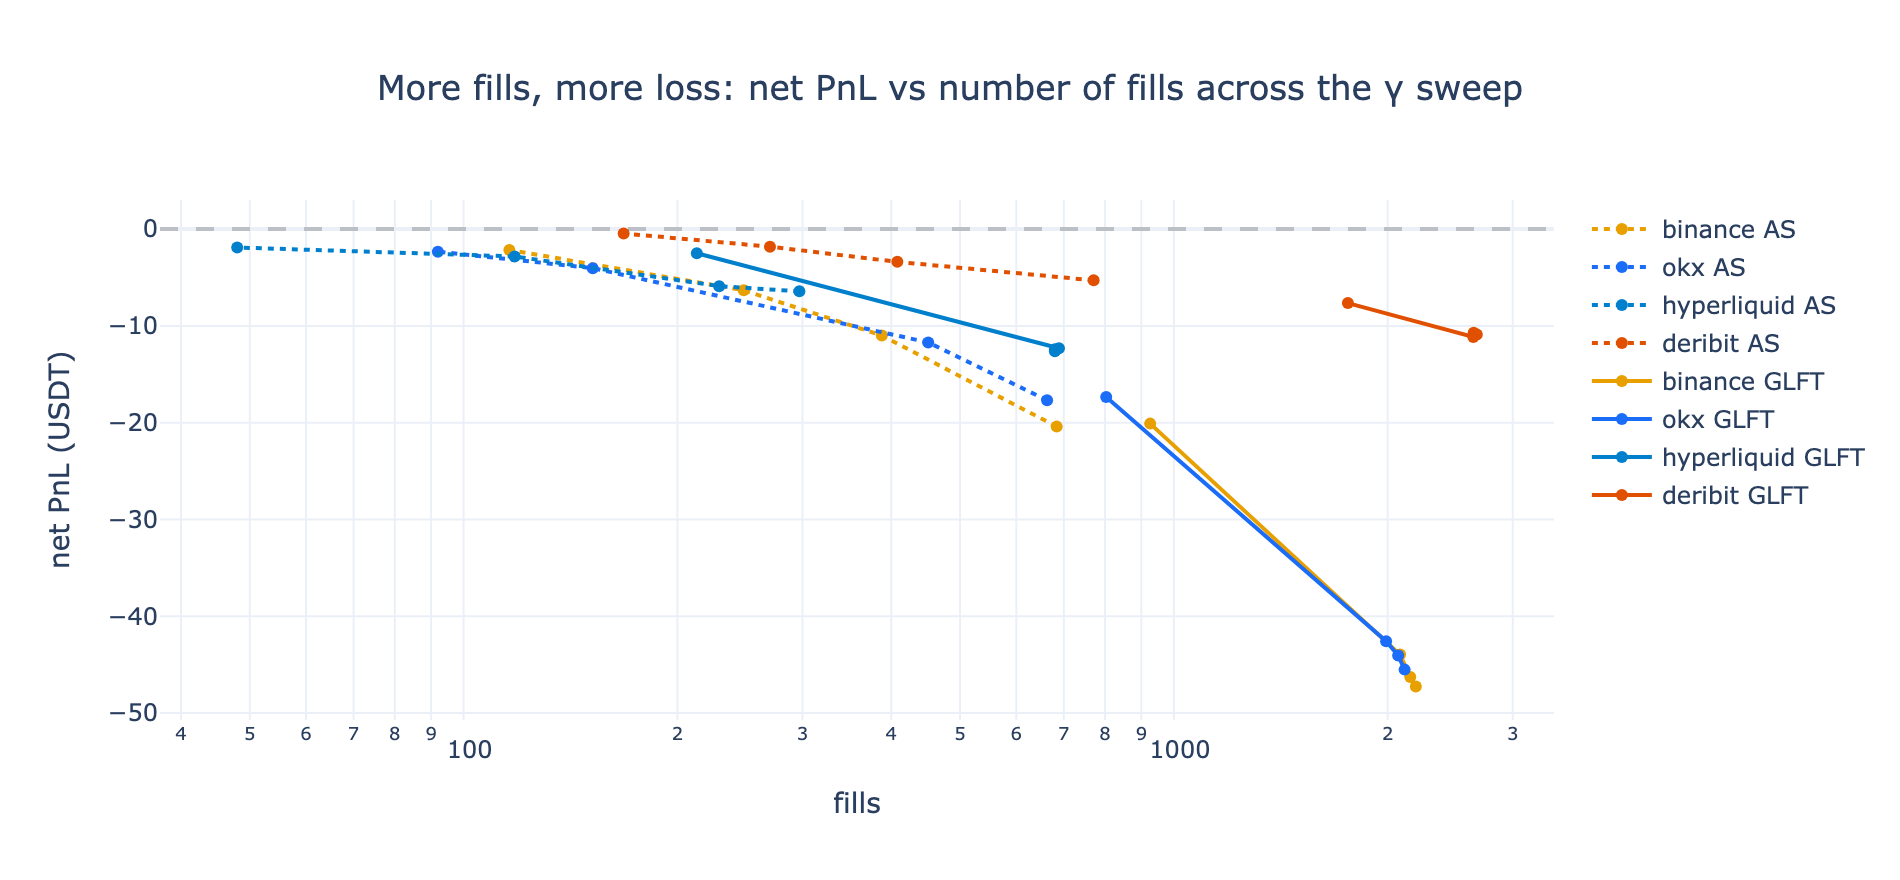

In [13]:
SWEEP = []
for venue, deltas in DELTAS.items():
    iid, c = f"BTCPERP.{venue.upper()}", CAL[venue]
    for g in GAMMAS:
        for model, strat in [("AS", AvellanedaStoikov(ASConfig(instrument_id=iid, kappa=c["kappa"], **{**AS_PARAMS, "gamma": g}))),
                             ("GLFT", GLFT(GLFTConfig(instrument_id=iid, kappa=c["kappa"], A=c["A"], **{**GLFT_PARAMS, "gamma": g})))]:
            r = run_backtest(venue, deltas, strat)
            SWEEP.append({"venue": venue, "model": model, "gamma": g, "net": r["final"], "fees": r["fees"],
                          "gross": r["gross"], "fills": r["fills"], "gross_per_fill": r["gross"] / max(r["fills"], 1),
                          "max_inv_btc": r["max_inv"]})
df_sweep = pd.DataFrame(SWEEP)
print(df_sweep.pivot_table(index=["venue", "gamma"], columns="model", values=["net", "fills"]).to_string(float_format="{:+.2f}".format))

fig = go.Figure()
for model, dash in (("AS", "dot"), ("GLFT", "solid")):
    for venue in DELTAS:
        d = df_sweep[(df_sweep.model == model) & (df_sweep.venue == venue)]
        fig.add_trace(go.Scatter(x=d["fills"], y=d["net"], mode="lines+markers", name=f"{venue} {model}",
                                 line=dict(color=COLORS.get(venue), dash=dash)))
fig.add_hline(y=0, line_dash="dash", line_color="rgba(0,0,0,0.2)")
fig.update_layout(title=dict(text="More fills, more loss: net PnL vs number of fills across the γ sweep", x=0.5),
                  template="plotly_white", height=440, xaxis_title="fills", yaxis_title="net PnL (USDT)", xaxis_type="log")
fig.show()
ipy_display(Image(fig.to_image(format="png", scale=2, width=950)))

## 10. Fees vs adverse selection

`gross_per_fill` is PnL before fees per fill (USDT per 0.001 BTC). Multiply by 1,000 for $ per BTC.
Deribit has a 0% maker fee, so its numbers isolate adverse selection: the tendency of fills to arrive just before the
price moves against the quote.

In [14]:
t = SUMMARY.copy()
t["gross_per_btc"] = t["gross_per_fill"] * 1000
t["fee_per_btc"] = t["fees"] / t["fills"].clip(lower=1) * 1000
print(t[["fills", "gross_per_btc", "fee_per_btc", "net_pnl"]].to_string(float_format="{:+.2f}".format))

                   fills  gross_per_btc  fee_per_btc  net_pnl
venue       model                                            
binance     AS       388         -12.63       +15.69   -10.99
            GLFT    2152          -5.83       +15.67   -46.26
okx         AS       451         -10.28       +15.69   -11.71
            GLFT    2069          -5.62       +15.67   -44.05
hyperliquid AS       229         -17.90        +7.84    -5.89
            GLFT     680         -10.73        +7.82   -12.61
deribit     AS       408          -8.30        +0.00    -3.39
            GLFT    2643          -4.05        +0.00   -10.70


## 11. Summary

In [15]:
print(SUMMARY["net_pnl"].unstack().to_string(float_format="{:+.3f}".format))
best = df_sweep.loc[df_sweep["net"].idxmax()]
print(f"\nBest net in sweep: {best['venue']} {best['model']} γ={best['gamma']:.0e} net={best['net']:+.3f} fills={int(best['fills'])}")

model            AS    GLFT
venue                      
binance     -10.991 -46.265
deribit      -3.386 -10.701
hyperliquid  -5.894 -12.613
okx         -11.714 -44.049

Best net in sweep: deribit AS γ=1e-03 net=-0.456 fills=168


> **Disclaimer:** worked example on one 4-hour session of real order-book data. Not investment advice or a production
> trading system. The fill-intensity calibration uses a price-excursion proxy (no trade prints), and both models assume fills
> are independent of subsequent price moves, which this data shows they are not.